In [1]:
# =============================================================================
# CELL 1 — configuration
# =============================================================================
import warnings
from time import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad
from scipy.special import gammaln
from sklearn.datasets import fetch_openml
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

ALPHA  = 0.05
B_CAL  = 100_000
N_NETS = 1200          # one observation = one trained network
SEED   = 123456789
N0     = 2             # starting index of the p-process

POOL_SIZE, N_SUB, HOLDOUT = 8000, 400, 3000
ARCH, MAX_ITER = (32,), 100

# Benchmark specification, fixed in advance: a round accuracy target of the kind
# a practitioner would state before running anything.  theta* is whatever the
# data make it; we do not choose b to obtain a particular crossing time.
BENCHMARK = 0.755
# Robustness sweep over neighbouring specifications (Figure 3).
BENCHMARK_GRID = [0.755, 0.760, 0.765]

print(f"config: alpha={ALPHA}, N={N_NETS}, arch={ARCH}, benchmark={BENCHMARK}")


config: alpha=0.05, N=1200, arch=(32,), benchmark=0.755


In [2]:
# =============================================================================
# CELL 2 — train the networks; each contributes one observation
# =============================================================================
print("Loading Fashion-MNIST ...")
X, y = fetch_openml("Fashion-MNIST", version=1, return_X_y=True, as_frame=False)
rs_load = np.random.default_rng(SEED)
keep = rs_load.choice(len(X), POOL_SIZE + HOLDOUT, replace=False)
X, y = X[keep] / 255.0, y[keep].astype(int)
X_pool, X_hold = X[:POOL_SIZE], X[POOL_SIZE:]
y_pool, y_hold = y[:POOL_SIZE], y[POOL_SIZE:]

sc = StandardScaler().fit(X_pool)
X_pool, X_hold = sc.transform(X_pool), sc.transform(X_hold)

print(f"pool {len(X_pool)}, holdout {len(X_hold)}, subsample/net {N_SUB}")
acc = np.empty(N_NETS)
t0 = time()
for i in range(N_NETS):
    rs = np.random.default_rng(SEED + i)
    sub = rs.choice(len(X_pool), N_SUB, replace=False)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        net = MLPClassifier(hidden_layer_sizes=ARCH, max_iter=MAX_ITER,
                            alpha=1e-4, random_state=SEED + i
                            ).fit(X_pool[sub], y_pool[sub])
    acc[i] = net.score(X_hold, y_hold)
    if (i + 1) % 200 == 0:
        print(f"  {i+1}/{N_NETS} [{time()-t0:.1f}s]")

print(f"\nheld-out accuracy: mean {acc.mean():.4f}, sd {acc.std(ddof=1):.4f}, "
      f"min {acc.min():.4f}, max {acc.max():.4f}")        

Loading Fashion-MNIST ...
pool 8000, holdout 3000, subsample/net 400
  200/1200 [15.3s]
  400/1200 [30.4s]
  600/1200 [45.3s]
  800/1200 [60.3s]
  1000/1200 [74.9s]
  1200/1200 [89.1s]

held-out accuracy: mean 0.7633, sd 0.0088, min 0.7310, max 0.7893


In [3]:
# =============================================================================
# CELL 3 — form the observation stream
# =============================================================================
def make_stream(accuracies, benchmark):
    """Standardised stream for H_0: mean accuracy = benchmark.

    The stream is oriented so the observed effect is positive.  The test is
    two-sided, so this is a relabelling; it lets the prior locations m be
    swept over positive values only.
    """
    y_raw = accuracies - benchmark
    if y_raw.mean() < 0:
        y_raw = -y_raw
    y_obs = y_raw / y_raw.std(ddof=1)
    return y_obs, float(y_obs.mean())          # sd is 1 after standardising

y_obs, theta_hat = make_stream(acc, BENCHMARK)
N_EVAL = len(y_obs)
cum, cum2 = np.cumsum(y_obs), np.cumsum(y_obs ** 2)

print(f"H_0: mean held-out accuracy = {BENCHMARK}")
print(f"stream: N = {N_EVAL},  observed standardised effect = {theta_hat:+.4f}")



H_0: mean held-out accuracy = 0.755
stream: N = 1200,  observed standardised effect = +0.9494


In [17]:
# =============================================================================
# CELL 4 — priors.  Scales are the conventional defaults and are stated once,
# so the labels cannot drift from the code.
# =============================================================================
def _cauchy(t): return -np.log(np.pi) - np.log1p(t * t)
def _gauss(t):  return -0.5 * np.log(2 * np.pi) - 0.5 * t * t
def _t5(t):
    nu = 5.0
    return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(nu * np.pi)
            - 0.5 * (nu + 1) * np.log1p(t * t / nu))

def scaled(base, r):
    logr = np.log(r)
    return lambda t: base(t / r) - logr

PRIOR_SCALES = {"Cauchy": 0.25,      # Rouder-JZS default 1 / np.sqrt(2)
                "Student-$t_5$": 0.5,
                "Gaussian": 0.25}
_BASE = {"Cauchy": _cauchy, "Student-$t_5$": _t5, "Gaussian": _gauss}
_COLOR = {"Cauchy": "tab:red", "Student-$t_5$": "tab:orange",
          "Gaussian": "tab:blue"}

PRIOR_SPECS = {
    f"{k} ($r={PRIOR_SCALES[k]:.3g}$)": (scaled(_BASE[k], PRIOR_SCALES[k]), _COLOR[k])
    for k in _BASE
}
m_values = [0.0, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0]

for lbl in PRIOR_SPECS:
    print(" ", lbl)
print("m grid:", m_values)


  Cauchy ($r=0.25$)
  Student-$t_5$ ($r=0.5$)
  Gaussian ($r=0.25$)
m grid: [0.0, 0.5, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0]


In [18]:
# =============================================================================
# CELL 5 — numerical core
# log A_n: peak-centred finite-window quadrature in log space.  No asymptotic
# branch: a fixed |z| cutoff is invalid once z is not large relative to sqrt(n),
# and quad on (0, inf) misses the peak at large n.  Verified against 60-digit
# arithmetic to ~1e-3 nats for n <= 3000, |z| <= 60.
# =============================================================================
def log_A_n(z, n):
    z, n = float(z), float(n)
    r_star = max((z + np.sqrt(z * z + 4.0 * (n - 1))) / 2.0, 1e-12)
    lmax = (n - 1) * np.log(r_star) - 0.5 * (r_star - z) ** 2
    sd = 1.0 / np.sqrt((n - 1) / (r_star * r_star) + 1.0)
    half = max(40.0 * sd, 12.0)
    f = lambda r: (np.exp((n - 1) * np.log(r) - 0.5 * (r - z) ** 2 - lmax)
                   if r > 0 else 0.0)
    I, _ = quad(f, max(r_star - half, 0.0), r_star + half,
                limit=400, points=[r_star])
    if not np.isfinite(I) or I <= 0:
        return -np.inf
    return (0.5 * z * z - (0.5 * n - 1) * np.log(2) - gammaln(0.5 * n)
            + lmax + np.log(I))

def make_log_A_table(n, z_max=60.0, num_points=1201):
    zg = np.linspace(-z_max, z_max, num_points)
    return zg, np.array([log_A_n(z, n) for z in zg])

def log_A_lookup(z, n, zg, lAg):
    z = float(z)
    return (float(np.interp(z, zg, lAg)) if -zg[-1] <= z <= zg[-1]
            else log_A_n(z, n))

def log_M_lebesgue(u, n):
    u, n = np.asarray(u, float), np.asarray(n, float)
    ratio = np.clip(u * u / n, 0.0, np.nextafter(1.0, 0.0))
    return 0.5 * np.log(2 * np.pi / n) - 0.5 * n * np.log1p(-ratio)

def log_M_mixture(u, m, n, log_prior, zg, lAg):
    """log of the mixture statistic.  The integrand's mode is located first and
    the window scaled by its local curvature; a fixed window centred at 0 loses
    the peak once |m| is large, which silently understates the evidence."""
    u, m = float(u), float(m)
    lg = lambda t: (-0.5 * n * t * t + log_A_lookup(t * u, n, zg, lAg)
                    + float(log_prior(t - m)))
    lo, hi = min(0.0, m) - 10.0, max(0.0, m) + 10.0
    scan = np.linspace(lo, hi, 400)
    sv = np.array([lg(t) for t in scan])
    j = int(np.argmax(sv))
    a, b = scan[max(j - 1, 0)], scan[min(j + 1, len(scan) - 1)]
    for _ in range(60):                                  # ternary refine
        m1, m2 = a + (b - a) / 3, b - (b - a) / 3
        if lg(m1) < lg(m2): a = m1
        else:               b = m2
    t_mode = 0.5 * (a + b)
    la = lg(t_mode)
    h = 1e-4 * max(1.0, abs(t_mode))
    curv = -(lg(t_mode + h) - 2 * la + lg(t_mode - h)) / (h * h)
    half = max(30.0 / np.sqrt(max(curv, 1e-12)), 3.0)
    f = lambda t: np.exp(lg(t) - la)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        edges = np.linspace(t_mode - half, t_mode + half, 9)
        I = sum(max(quad(f, edges[k], edges[k + 1], limit=200)[0], 0.0)
                for k in range(len(edges) - 1))
    return la + np.log(I) if I > 0 else -np.inf

def u_cap(n, zc): return np.sqrt(zc * zc * n / ((n - 1) + zc * zc))

def log_M_on_u_grid(m, n, log_prior, zg, lAg, n_u=200):
    umax = min(np.sqrt(n) - 1e-3, u_cap(n, zg[-1]))
    if n <= 4:
        core = np.linspace(-umax, umax, n_u)
        edge = umax - np.geomspace(1e-4, 0.05, 40)
        ug = np.unique(np.concatenate([core, edge, -edge]))
    else:
        ug = np.linspace(-umax, umax, n_u)
    return ug, np.array([log_M_mixture(u, m, n, log_prior, zg, lAg) for u in ug])

# --- p-processes, evaluated at the running maximum of the wealth -------------
def ville_p(log_M):
    return np.exp(-np.maximum(np.maximum.accumulate(np.asarray(log_M, float)), 0.0))

def eville_p(log_M, log_cal, w=None):
    w = CAL_W if w is None else w
    run = np.maximum.accumulate(np.asarray(log_M, float))
    d = np.asarray(log_cal, float)[None, :] - run[:, None]
    return np.clip((np.exp(np.minimum(d, 0.0)) * w[None, :]).sum(axis=1), 0.0, 1.0)

def first_crossing(p, ns, alpha=ALPHA):
    pos = np.flatnonzero(np.isfinite(p) & (np.asarray(p, float) <= alpha))
    return int(np.asarray(ns, int)[pos[0]]) if pos.size else None



In [19]:
# =============================================================================
# CELL 6 — calibration, with the exact martingale identity as a self-check.
# For a proper prior M_{n0} is a mean-one martingale, so E_0[M_{n0}] = 1.
# A Monte Carlo mean far from 1 means the quadrature has lost mass and the
# calibration cannot be trusted -- this is the check that catches the failure
# mode at large |m|.
# =============================================================================
n_grid = np.array(sorted(set(list(range(N0, 121)) +
                            list(range(125, 501, 5)) +
                            list(range(510, N_EVAL + 1, 25)) + [N_EVAL])), int)
print(f"n grid: {len(n_grid)} points, {n_grid[0]}-{n_grid[-1]} (n0={N0})")

print("tabulating log A_n ...")
t0 = time()
A_TABLE = {int(n): make_log_A_table(int(n)) for n in sorted(set([N0, 2] + n_grid.tolist()))}
print(f"  done [{time()-t0:.1f}s]")

rngc = np.random.default_rng(20260601)
Yc = rngc.standard_normal((B_CAL, N0))
u0c = Yc.sum(axis=1) / np.sqrt((Yc ** 2).sum(axis=1))
z0, lA0 = A_TABLE[N0]

NV = 400
_x, _w = np.polynomial.legendre.leggauss(NV)
w_nodes = (np.pi / 2) * _x
_logc = gammaln(N0 / 2) - 0.5 * np.log(np.pi) - gammaln((N0 - 1) / 2)
_dens = np.exp(_logc + (N0 - 2) * np.log(np.cos(w_nodes)))
CAL_W = _w * (np.pi / 2) * _dens               # sums to 1
u_cal = np.sqrt(N0) * np.sin(w_nodes)
print(f"calibration nodes: {NV}, weight sum = {CAL_W.sum():.10f}")

CAL, MART = {}, {}
for label, (lp, _) in PRIOR_SPECS.items():
    for m in m_values:
        lc = np.array([log_M_mixture(u, m, N0, lp, z0, lA0) for u in u_cal])
        CAL[(label, m)] = lc
        MART[(label, m)] = float(np.sum(CAL_W * np.exp(np.minimum(lc, 700.0))))
        if not (0.97 <= MART[(label, m)] <= 1.03):
            print(f"    WARNING {label} m={m}: E_0[M_{N0}] = {MART[(label,m)]:.4f}")
print(f"martingale check range "
      f"[{min(MART.values()):.4f}, {max(MART.values()):.4f}]")

logcal_leb = log_M_lebesgue(u_cal, N0)

# Lebesgue baseline, calibrated on the same sample
logM0_leb = log_M_lebesgue(u0c, N0)
def lebesgue_p(log_M):
    return eville_p(log_M, logcal_leb)

n grid: 224 points, 2-1200 (n0=2)
tabulating log A_n ...
  done [51.7s]
calibration nodes: 400, weight sum = 1.0000000000
martingale check range [0.9707, 1.0008]


In [20]:
# =============================================================================
# CELL 7 — paths for every (prior, location) at the stated specification
# =============================================================================
u_all = cum[n_grid - 1] / np.sqrt(cum2[n_grid - 1])
p_leb = lebesgue_p(log_M_lebesgue(u_all, n_grid))
LEB_REJECT = first_crossing(p_leb, n_grid)
print(f"Lebesgue baseline rejects at n = {LEB_REJECT} "
      f"({LEB_REJECT/N_EVAL:.0%} of the stream)")

results = {}
t0 = time()
for label, (lp, _) in PRIOR_SPECS.items():
    for m in m_values:
        lM = np.array([log_M_mixture(float(u_all[i]), m, int(n), lp,
                                     *A_TABLE[int(n)])
                       for i, n in enumerate(n_grid)])
        results[(label, m)] = (ville_p(lM), eville_p(lM, CAL[(label, m)]))
    print(f"  {label} [{time()-t0:.1f}s]")


Lebesgue baseline rejects at n = 15 (1% of the stream)
  Cauchy ($r=0.25$) [199.6s]
  Student-$t_5$ ($r=0.5$) [306.7s]
  Gaussian ($r=0.25$) [429.6s]


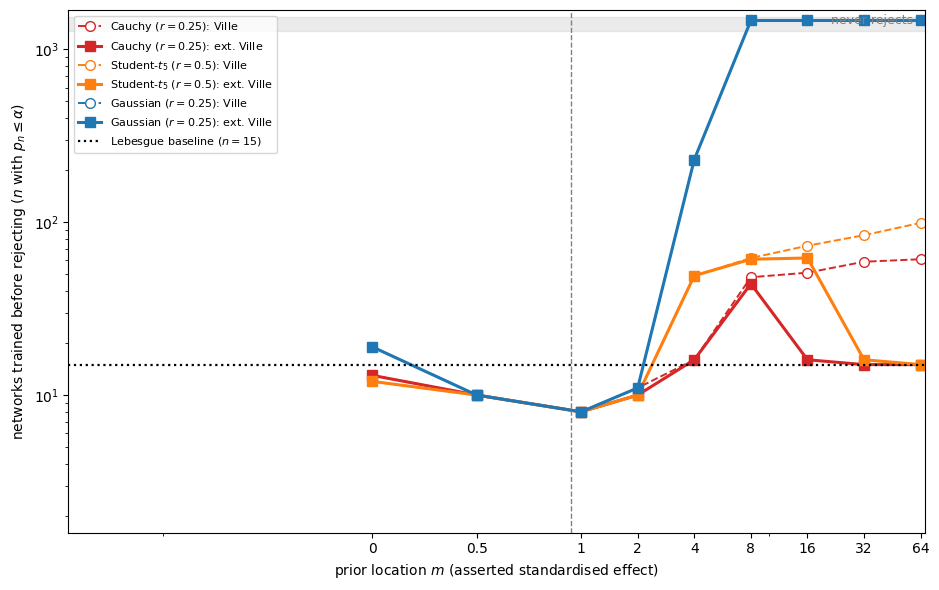

In [21]:
# =============================================================================
# CELL 8 — FIGURE 1: first rejection against prior location
# =============================================================================
NOREJ = N_EVAL * 1.22
fig, ax = plt.subplots(figsize=(9.5, 6))
for label, (_, color) in PRIOR_SPECS.items():
    nV  = [first_crossing(results[(label, m)][0], n_grid) for m in m_values]
    nEV = [first_crossing(results[(label, m)][1], n_grid) for m in m_values]
    ax.plot(m_values, [NOREJ if v is None else v for v in nV], "--o",
            color=color, markerfacecolor="white", ms=7, lw=1.4,
            label=f"{label}: Ville")
    ax.plot(m_values, [NOREJ if v is None else v for v in nEV], "-s",
            color=color, ms=7, lw=2.2, label=f"{label}: ext. Ville")
ax.axhline(LEB_REJECT, color="black", ls=":", lw=1.6,
           label=f"Lebesgue baseline ($n={LEB_REJECT}$)")
ax.axvline(theta_hat, color="gray", ls="--", lw=1.0)
ax.axhspan(N_EVAL * 1.06, NOREJ * 1.05, color="lightgray", alpha=0.45, zorder=0)
ax.text(m_values[-1], NOREJ, "never rejects  ", ha="right", va="center",
        fontsize=9, color="gray")
ax.set_xscale("symlog", linthresh=1.0)
ax.set_yscale("log")
ax.set_xticks(m_values); ax.set_xticklabels([f"{m:g}" for m in m_values])
ax.set_xlabel(r"prior location $m$ (asserted standardised effect)")
ax.set_ylabel(r"networks trained before rejecting ($n$ with $p_n\leq\alpha$)")
ax.set_ylim(n_grid[0] * 0.8, NOREJ * 1.15) 
#ax.set_ylim(0, NOREJ * 1.10); ax.grid(True, alpha=0.25)
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
fig.savefig("nn_first_rejection_vs_m.pdf", bbox_inches="tight")
plt.show()

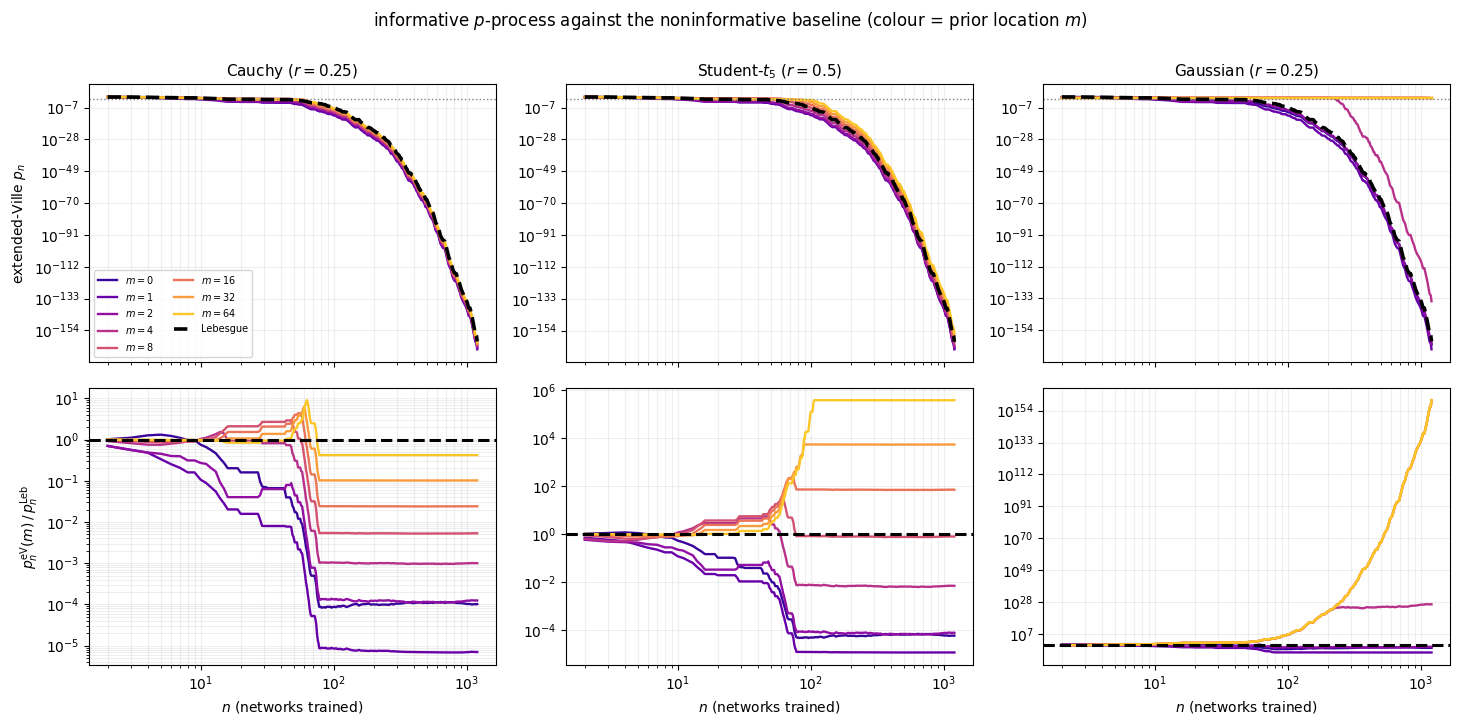

In [22]:
# =============================================================================
# CELL 9 — FIGURE 2: reversion of the informative p-process to the baseline
# =============================================================================
m_show = [0.0, 1.0, 2.0, 4.0, 8.0, 16.0, 32.0, 64.0]
cmap = plt.cm.plasma
cols = {m: cmap(0.08 + 0.80 * i / (len(m_show) - 1)) for i, m in enumerate(m_show)}

fig, axes = plt.subplots(2, len(PRIOR_SPECS),
                         figsize=(4.9 * len(PRIOR_SPECS), 7.2),
                         sharex=True)

for j, (label, _) in enumerate(PRIOR_SPECS.items()):
    ax = axes[0, j]
    for m in m_show:
        ax.plot(n_grid, results[(label, m)][1], "-", color=cols[m], lw=1.7,
                label=f"$m={m:g}$")
    ax.plot(n_grid, p_leb, "--", color="black", lw=2.6, zorder=10,
            label="Lebesgue")
    ax.axhline(ALPHA, color="gray", ls=":", lw=1.0)
    ax.set_yscale("log"); ax.set_title(label, fontsize=11)
    ax.grid(True, which="both", alpha=0.2)
    if j == 0:
        ax.set_ylabel(r"extended-Ville $p_n$")
        ax.legend(fontsize=7, loc="lower left", ncol=2)

    ax = axes[1, j]
    for m in m_show:
        ax.plot(n_grid, results[(label, m)][1] / np.maximum(p_leb, 1e-300),
                "-", color=cols[m], lw=1.7)
    ax.axhline(1.0, color="black", ls="--", lw=2.2, zorder=10)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$n$ (networks trained)")
    ax.grid(True, which="both", alpha=0.2)
    if j == 0:
        ax.set_ylabel(r"$p_n^{\rm eV}(m)\,/\,p_n^{\rm Leb}$")

fig.suptitle("informative $p$-process against the noninformative baseline "
             "(colour = prior location $m$)", fontsize=12, y=1.00)
fig.tight_layout()
fig.savefig("nn_pvalue_trajectories.pdf", bbox_inches="tight")
plt.show()

  b=0.755 (theta*=+0.949): Lebesgue n=15 [330.4s]
  b=0.760 (theta*=+0.380): Lebesgue n=145 [489.1s]
  b=0.765 (theta*=+0.189): Lebesgue n=480 [601.2s]


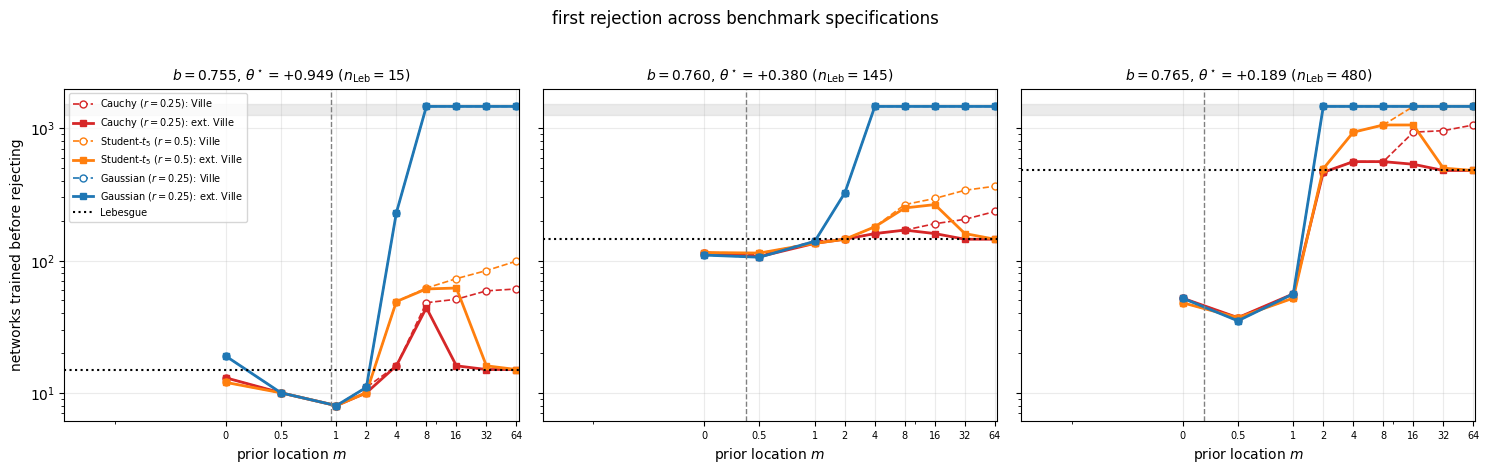

In [23]:
# =============================================================================
# CELL 10 — FIGURE 3: robustness across specifications.
# The calibration depends on (prior, m, n0) under H_0 only, not on the
# benchmark, so CAL is reused unchanged.
# =============================================================================
results_all, leb_all, theta_all = {}, {}, {}
t0 = time()
for b in BENCHMARK_GRID:
    ys, th = make_stream(acc, b)
    theta_all[b] = th
    c1, c2 = np.cumsum(ys), np.cumsum(ys ** 2)
    ua = c1[n_grid - 1] / np.sqrt(c2[n_grid - 1])
    leb_all[b] = first_crossing(lebesgue_p(log_M_lebesgue(ua, n_grid)), n_grid)
    for label, (lp, _) in PRIOR_SPECS.items():
        for m in m_values:
            lM = np.array([log_M_mixture(float(ua[i]), m, int(n), lp,
                                         *A_TABLE[int(n)])
                           for i, n in enumerate(n_grid)])
            results_all[(b, label, m)] = (ville_p(lM),
                                          eville_p(lM, CAL[(label, m)]))
    print(f"  b={b:.3f} (theta*={th:+.3f}): Lebesgue n={leb_all[b]} "
          f"[{time()-t0:.1f}s]")

fig, axes = plt.subplots(1, len(BENCHMARK_GRID),
                         figsize=(5.0 * len(BENCHMARK_GRID), 4.6), sharey=True)
for j, b in enumerate(BENCHMARK_GRID):
    ax = axes[j]
    for label, (_, color) in PRIOR_SPECS.items():
        nV  = [first_crossing(results_all[(b, label, m)][0], n_grid) for m in m_values]
        nEV = [first_crossing(results_all[(b, label, m)][1], n_grid) for m in m_values]
        ax.plot(m_values, [NOREJ if v is None else v for v in nV], "--o",
                color=color, markerfacecolor="white", ms=5, lw=1.2,
                label=f"{label}: Ville" if j == 0 else None)
        ax.plot(m_values, [NOREJ if v is None else v for v in nEV], "-s",
                color=color, ms=5, lw=2.0,
                label=f"{label}: ext. Ville" if j == 0 else None)
    ax.axhline(leb_all[b], color="black", ls=":", lw=1.5,
               label="Lebesgue" if j == 0 else None)
    ax.axvline(theta_all[b], color="gray", ls="--", lw=1.0)
    ax.axhspan(N_EVAL * 1.06, NOREJ * 1.05, color="lightgray", alpha=0.45)
    ax.set_xscale("symlog", linthresh=1.0); ax.set_yscale("log")
    ax.set_xticks(m_values)
    ax.set_xticklabels([f"{m:g}" for m in m_values], fontsize=7)
    ax.set_xlabel(r"prior location $m$")
    ax.set_title(rf"$b={b:.3f}$, $\theta^\star={theta_all[b]:+.3f}$ "
                 rf"($n_{{\rm Leb}}={leb_all[b]}$)", fontsize=10)
    ax.grid(True, alpha=0.25)
    if j == 0:
        ax.set_ylabel("networks trained before rejecting")
        ax.legend(fontsize=7, loc="upper left")
fig.suptitle("first rejection across benchmark specifications", y=1.02)
fig.tight_layout()
fig.savefig("nn_first_rejection_by_benchmark.pdf", bbox_inches="tight")
plt.show()